# Práctica 8. Aplicación de filtros

## Universidad Autónoma de Nuevo León
## Facultad de Ingeniería Mecánica y Eléctrica

Integrantes:
- Cristian Alexis De La Cruz Cabrera 2065212
- Octavio Rodríguez Cázares 2100243

Grupo: 309
Hora: N4 / Día: Miércoles

Docence : Ing. Noe Adiel Ponce Moreno


In [1]:
from google.colab import files

archivos = files.upload()


Saving imagen 2.jpg to imagen 2.jpg
Saving Imagen 1.jpg to Imagen 1.jpg


Las dos imágenes se cargaron correctamente.

PARTE I: FILTROS ESPACIALES


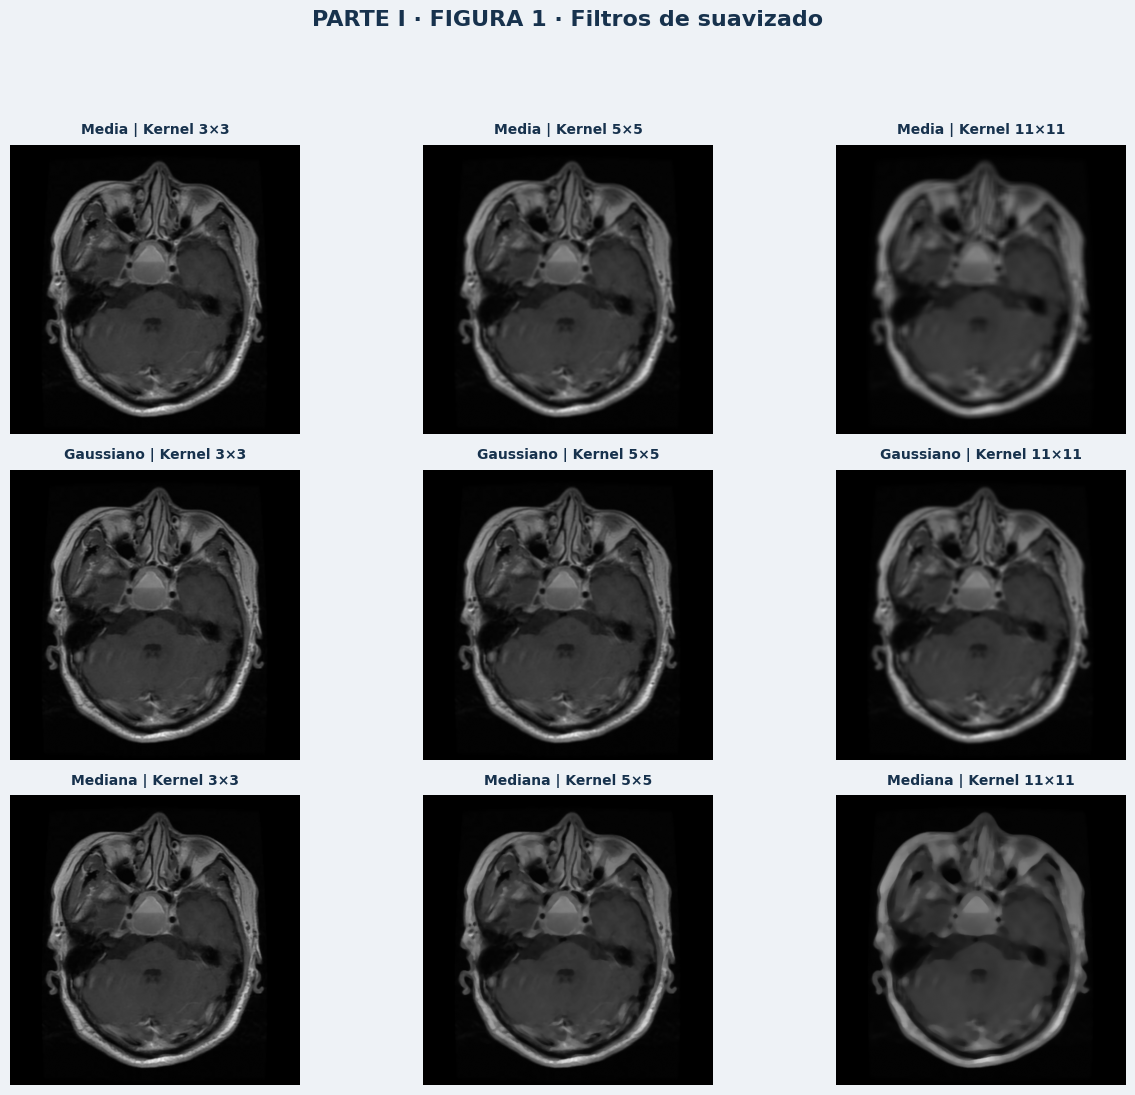

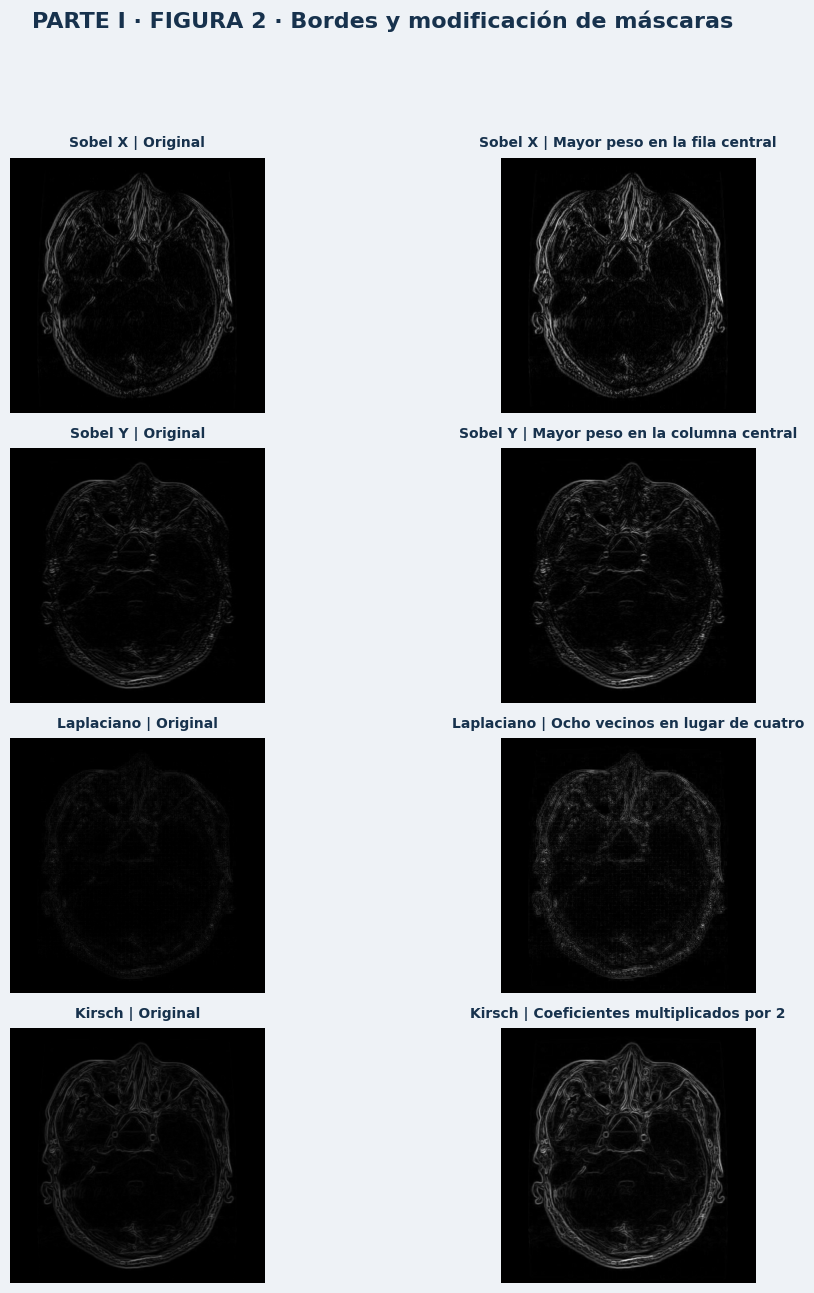


Sobel X
Máscara original:
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
Máscara modificada:
 [[-1.  0.  1.]
 [-4.  0.  4.]
 [-1.  0.  1.]]

Sobel Y
Máscara original:
 [[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]
Máscara modificada:
 [[-1. -4. -1.]
 [ 0.  0.  0.]
 [ 1.  4.  1.]]

Laplaciano
Máscara original:
 [[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]
Máscara modificada:
 [[ 1.  1.  1.]
 [ 1. -8.  1.]
 [ 1.  1.  1.]]

Kirsch: ejemplo de una orientación
Máscara original:
 [[ 5.  5.  5.]
 [-3.  0. -3.]
 [-3. -3. -3.]]
Máscara modificada:
 [[10. 10. 10.]
 [-6.  0. -6.]
 [-6. -6. -6.]]


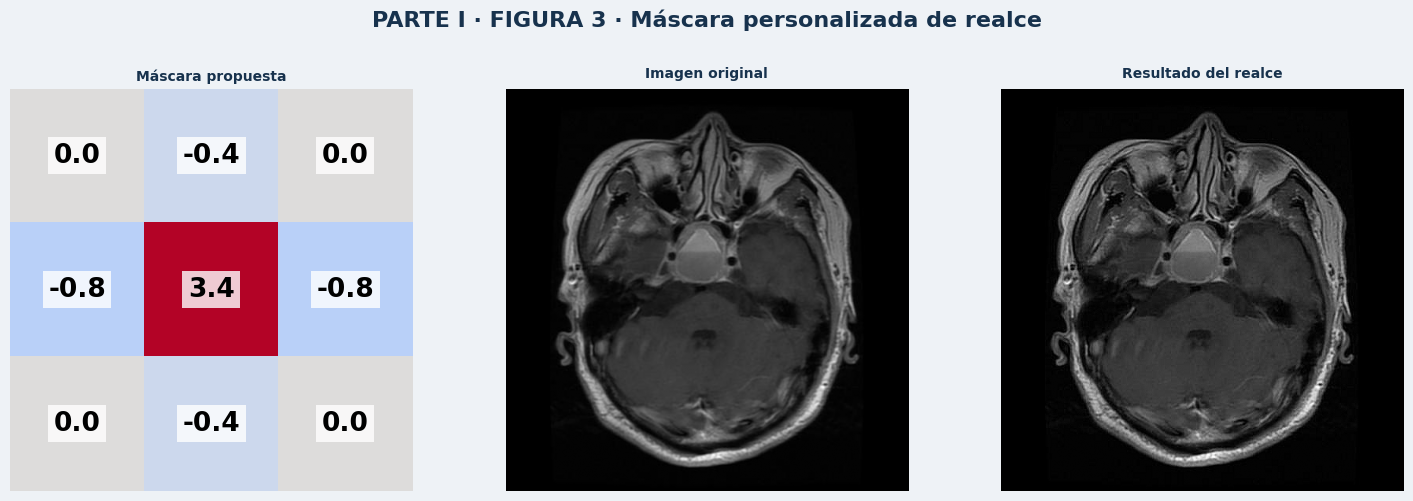

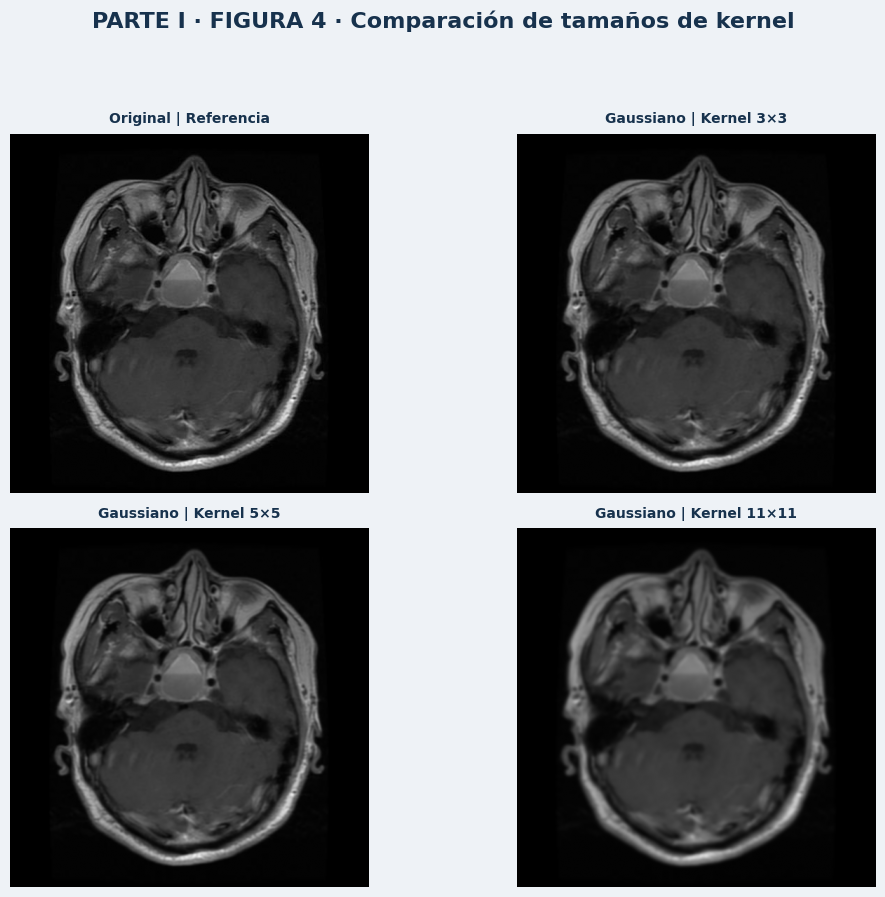


PARTE II: FILTROS EN EL DOMINIO DE LA FRECUENCIA


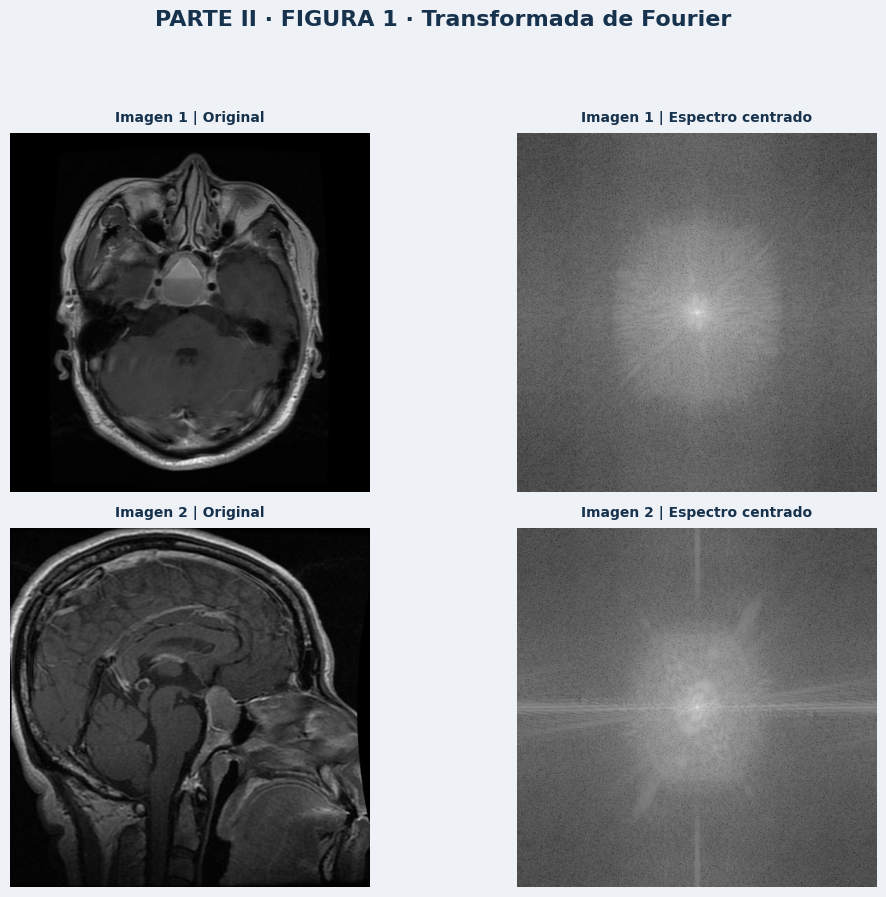

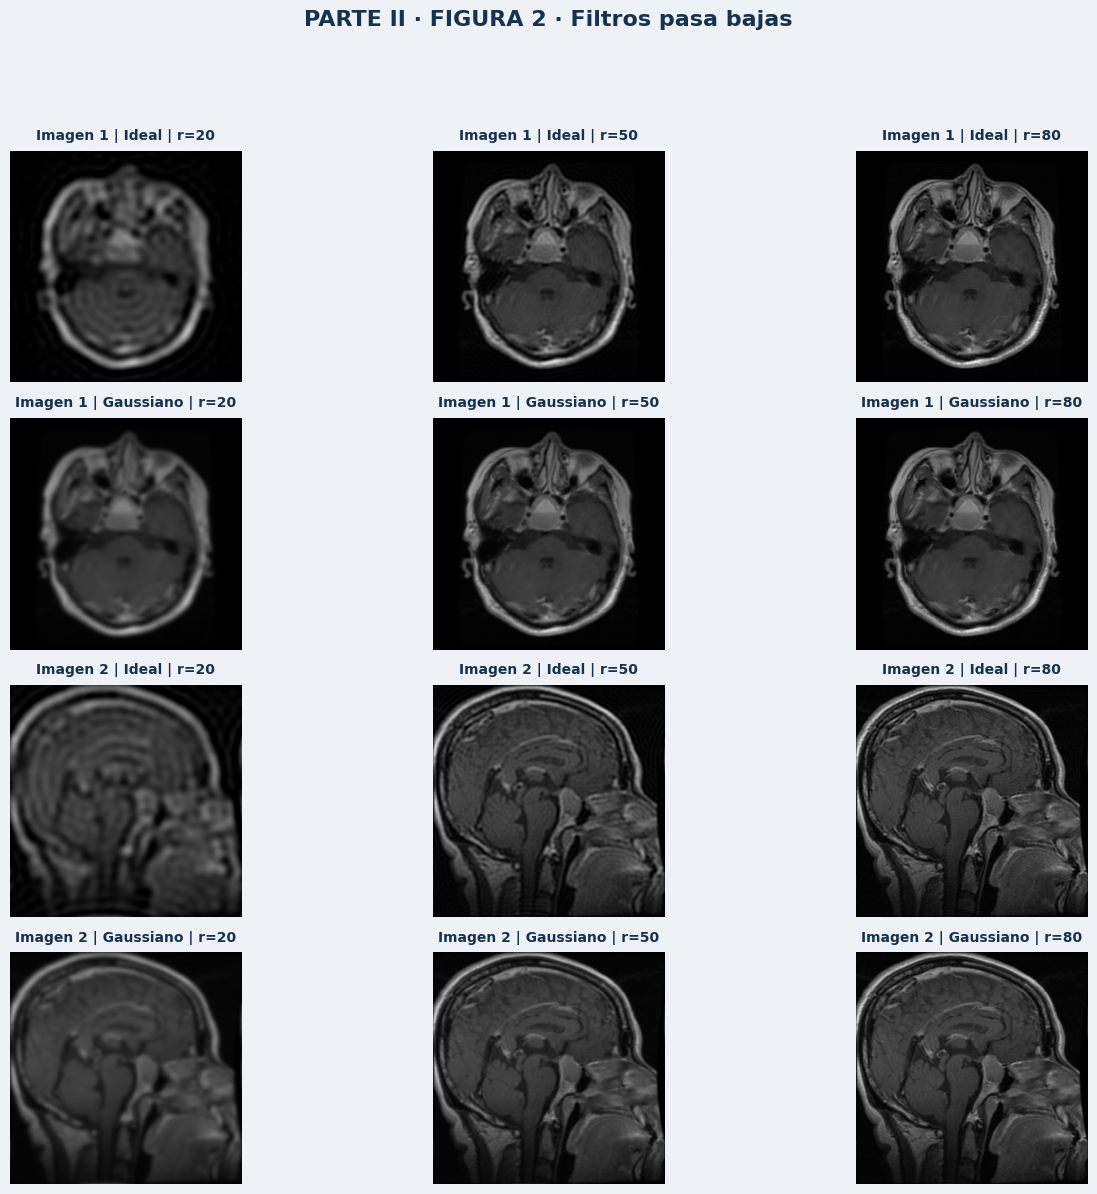

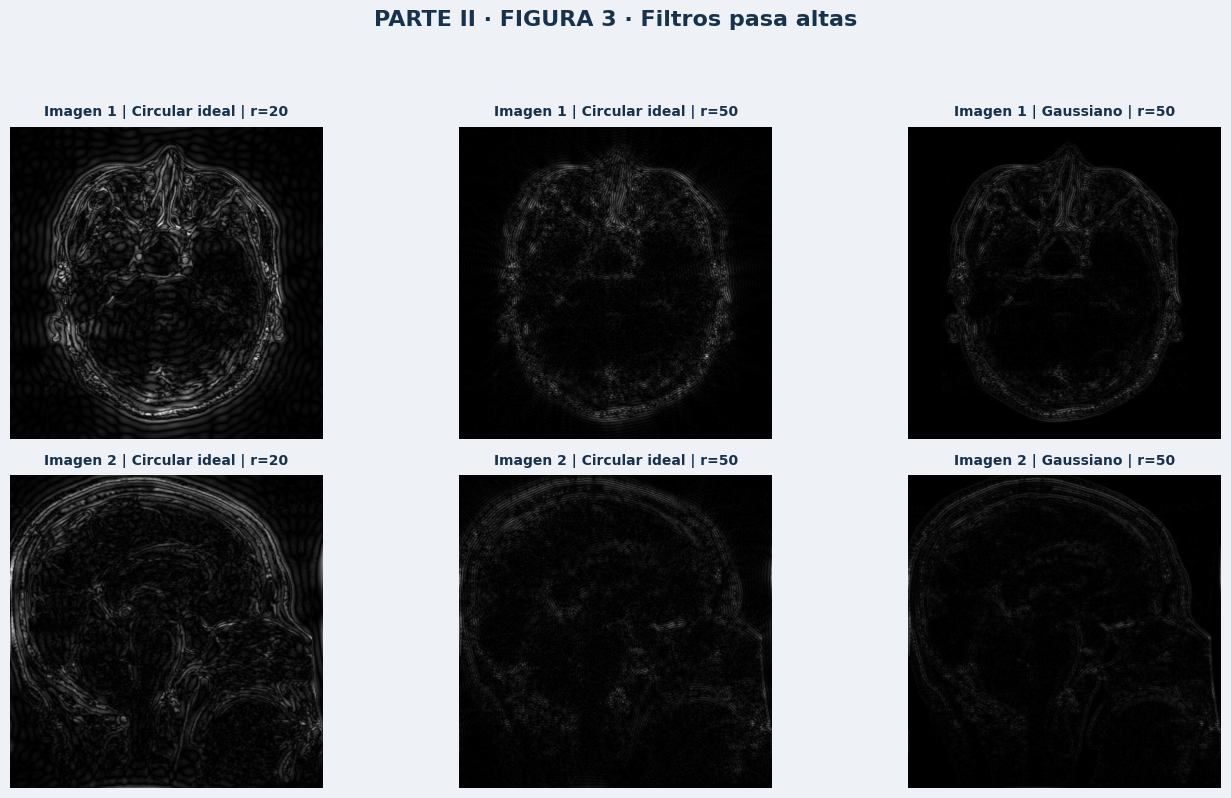

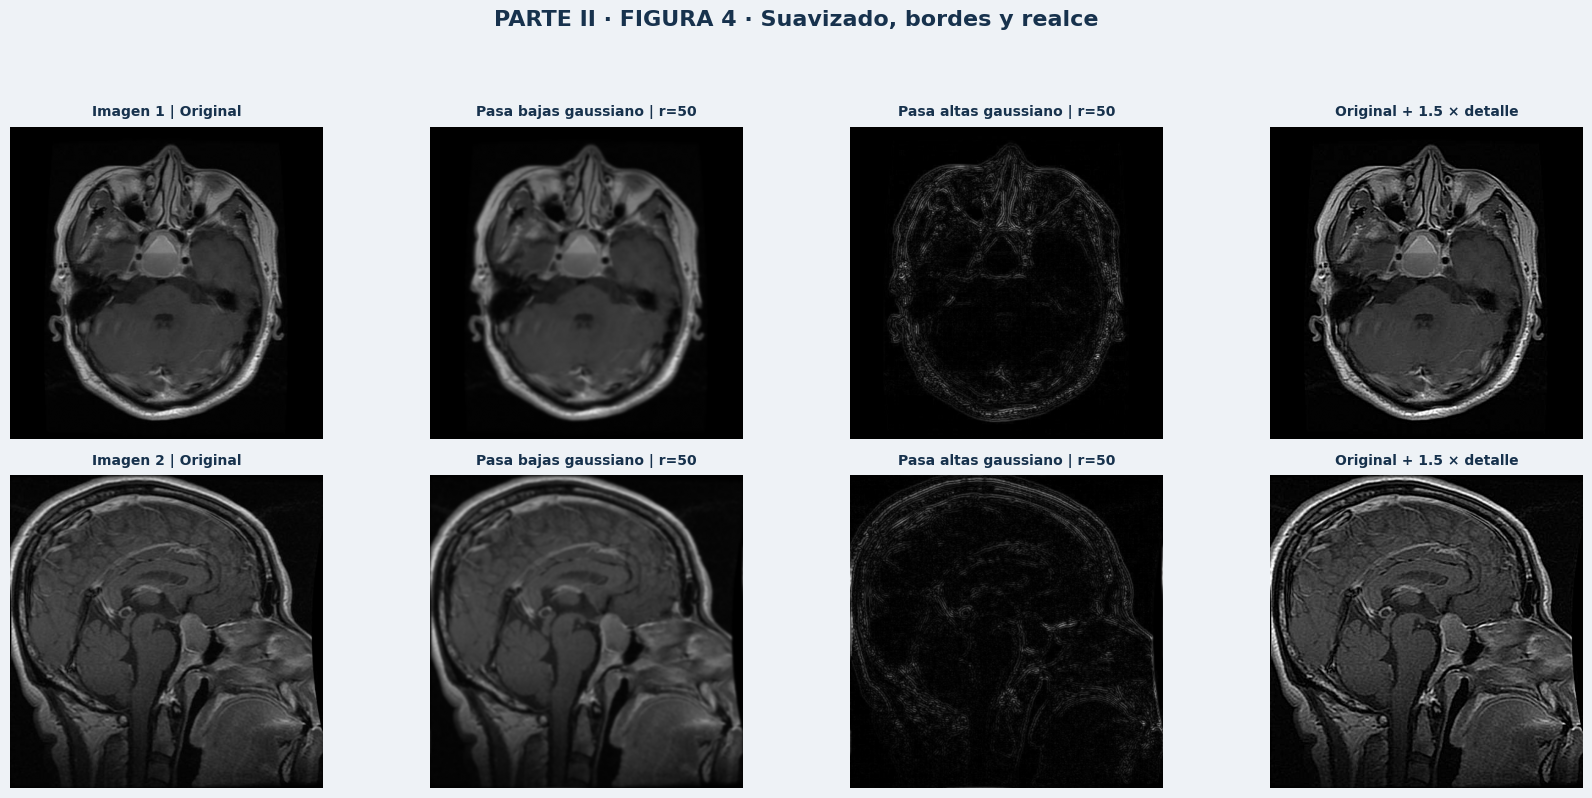

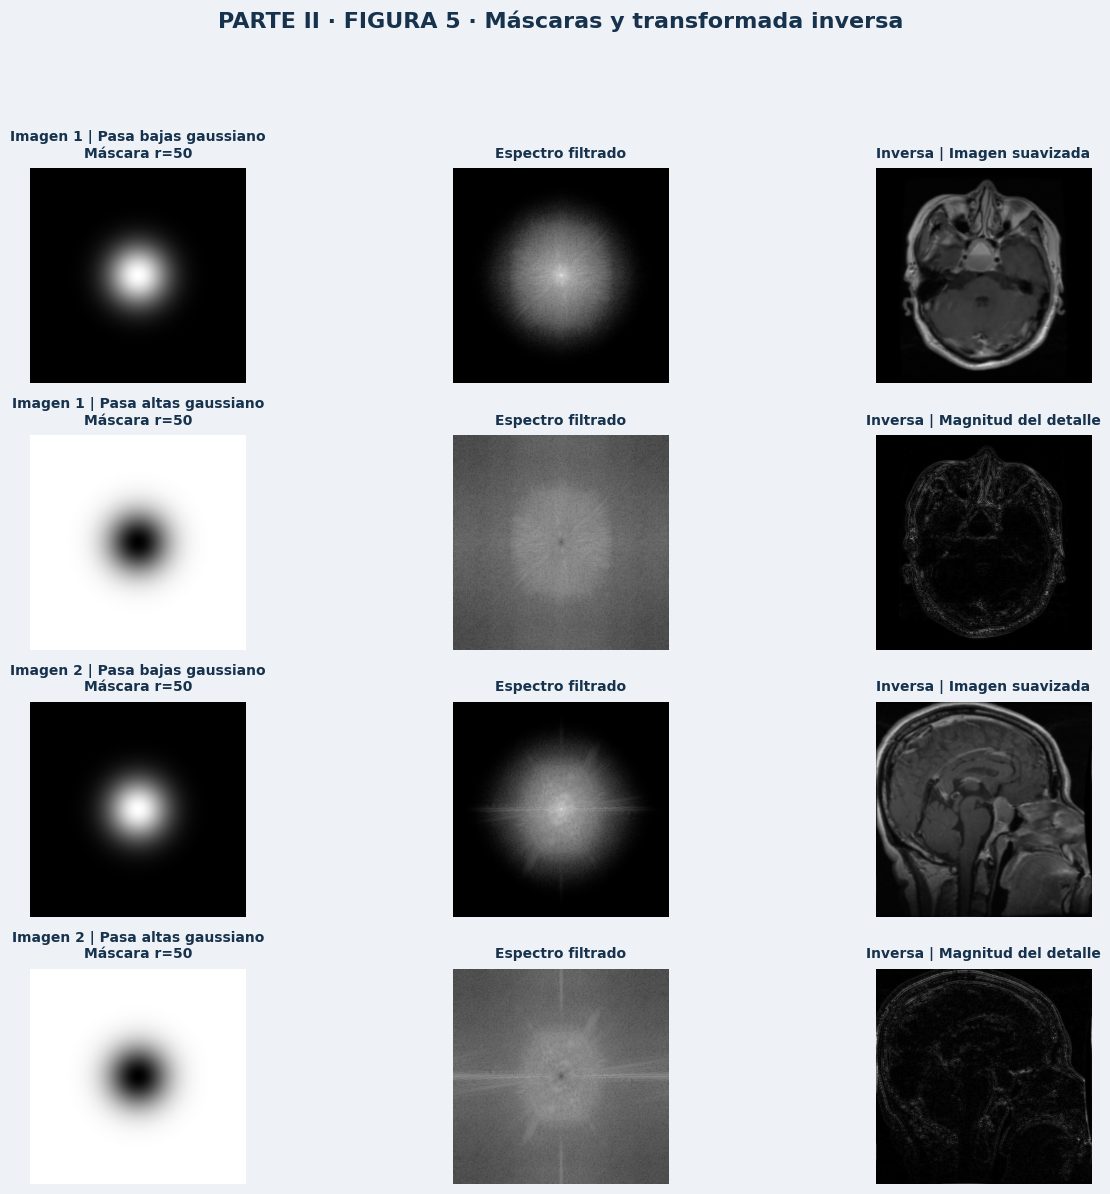

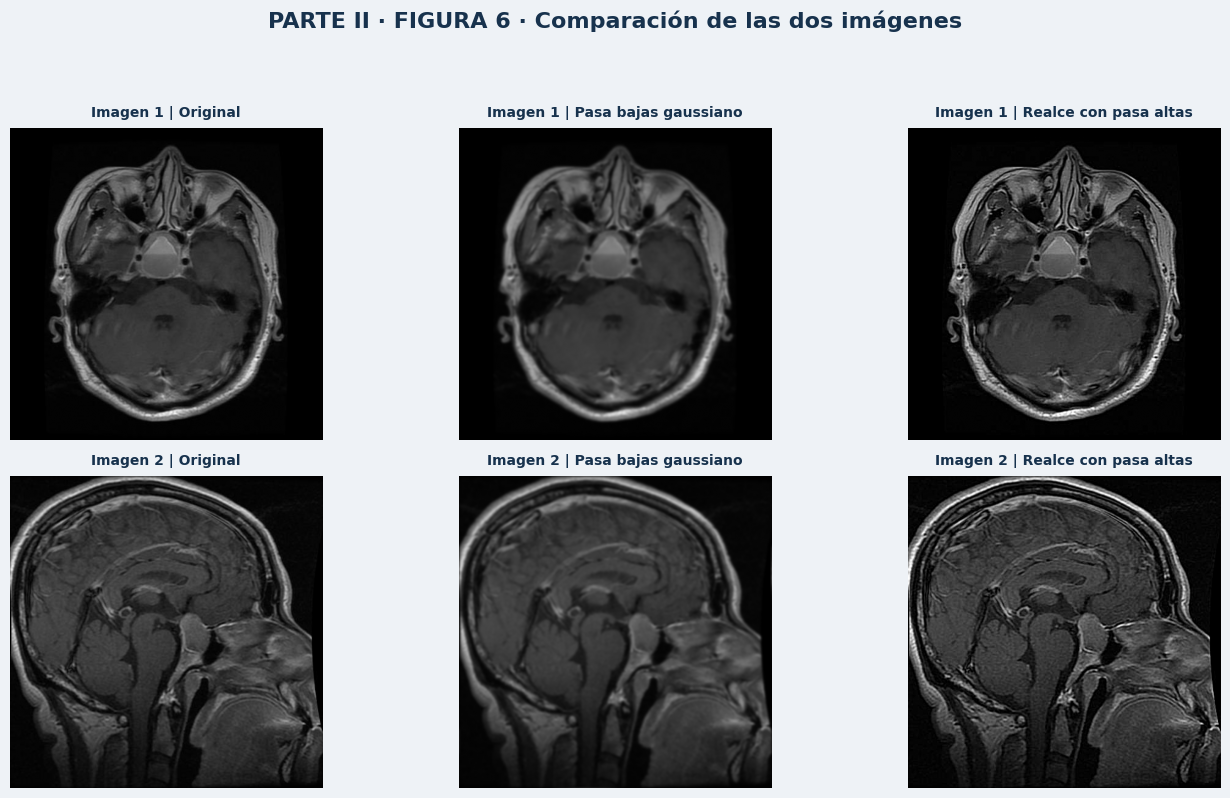


Práctica terminada.
Parte I: cuatro figuras.
Parte II: seis figuras.


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path



def cargar_imagen(nombre_buscado):

    coincidencias = [
        archivo
        for archivo in Path(".").iterdir()
        if archivo.is_file()
        and archivo.name.lower() == nombre_buscado.lower()
    ]

    if not coincidencias:
        raise FileNotFoundError(
            f"No se encontró {nombre_buscado}. "
            "Revisa los archivos subidos."
        )

    imagen = cv2.imread(
        str(coincidencias[0]),
        cv2.IMREAD_GRAYSCALE
    )

    if imagen is None:
        raise ValueError(
            f"No se pudo leer {coincidencias[0].name}"
        )

    return imagen


imagen_1 = cargar_imagen("imagen 1.jpg")
imagen_2 = cargar_imagen("imagen 2.jpg")
imagenes = [imagen_1, imagen_2]

print("Las dos imágenes se cargaron correctamente.")


plt.rcParams.update({
    "figure.facecolor": "#eef2f6",
    "axes.facecolor": "#eef2f6",
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10
})


def crear_figura(titulo, filas, columnas, tamano):

    fig, ejes = plt.subplots(
        filas,
        columnas,
        figsize=tamano,
        squeeze=False
    )

    fig.suptitle(
        titulo,
        fontsize=16,
        fontweight="bold",
        color="#17324d",
        y=0.99
    )

    for eje in ejes.ravel():
        eje.axis("off")

    return fig, ejes


def mostrar(eje, imagen, titulo, maximo=255):

    eje.imshow(
        imagen,
        cmap="gray",
        vmin=0,
        vmax=maximo
    )

    eje.set_title(
        titulo,
        color="#17324d",
        fontweight="bold",
        pad=8
    )

    eje.axis("off")


def finalizar(fig):

    fig.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()
    plt.close(fig)


def filtrar_mascara(imagen, mascara):

    return cv2.filter2D(
        imagen,
        cv2.CV_32F,
        mascara
    )


def crear_kirsch():

    vecinos = [
        (0, 0), (0, 1), (0, 2), (1, 2),
        (2, 2), (2, 1), (2, 0), (1, 0)
    ]

    mascaras = []

    for direccion in range(8):

        mascara = np.full((3, 3), -3, dtype=np.float32)
        mascara[1, 1] = 0

        for j in range(3):
            fila, columna = vecinos[(direccion + j) % 8]
            mascara[fila, columna] = 5

        mascaras.append(mascara)

    return mascaras


def aplicar_kirsch(imagen, mascaras):

    respuestas = [
        filtrar_mascara(imagen, mascara)
        for mascara in mascaras
    ]

    return np.maximum(
        np.maximum.reduce(respuestas),
        0
    )


def transformar(imagen):

    return np.fft.fftshift(
        np.fft.fft2(imagen.astype(np.float64))
    )


def espectro(transformada):

    return np.log1p(np.abs(transformada))


def reconstruir(transformada, mascara):

    return np.fft.ifft2(
        np.fft.ifftshift(transformada * mascara)
    ).real


def distancia_centro(forma):

    filas, columnas = forma
    y, x = np.ogrid[:filas, :columnas]

    return np.sqrt(
        (y - filas // 2) ** 2 +
        (x - columnas // 2) ** 2
    )


def pb_ideal(distancia, radio):

    return (distancia <= radio).astype(np.float64)


def pb_gaussiano(distancia, radio):

    return np.exp(
        -(distancia ** 2) / (2 * radio ** 2)
    )


# ============================================================
# PARTE I: FILTROS ESPACIALES
# ============================================================

img_gray = imagen_1

print("\nPARTE I: FILTROS ESPACIALES")


# ------------------------------------------------------------
# FIGURA 1: FILTROS DE SUAVIZADO
# ------------------------------------------------------------

tamanos = [3, 5, 11]

suavizados = {
    "Media": [],
    "Gaussiano": [],
    "Mediana": []
}

for k in tamanos:

    suavizados["Media"].append(
        cv2.blur(img_gray, (k, k))
    )

    suavizados["Gaussiano"].append(
        cv2.GaussianBlur(img_gray, (k, k), sigmaX=0)
    )

    suavizados["Mediana"].append(
        cv2.medianBlur(img_gray, k)
    )

fig, ejes = crear_figura(
    "PARTE I · FIGURA 1 · Filtros de suavizado",
    3, 3, (13, 11)
)

for fila, (nombre, resultados) in enumerate(suavizados.items()):
    for columna, k in enumerate(tamanos):

        mostrar(
            ejes[fila, columna],
            resultados[columna],
            f"{nombre} | Kernel {k}×{k}"
        )

finalizar(fig)


# ------------------------------------------------------------
# FIGURA 2: DETECCIÓN DE BORDES Y MODIFICACIÓN DE MÁSCARAS
# ------------------------------------------------------------

sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)

laplaciano = np.array([
    [0,  1, 0],
    [1, -4, 1],
    [0,  1, 0]
], dtype=np.float32)

sobel_x_mod = np.array([
    [-1, 0, 1],
    [-4, 0, 4],
    [-1, 0, 1]
], dtype=np.float32)

sobel_y_mod = np.array([
    [-1, -4, -1],
    [ 0,  0,  0],
    [ 1,  4,  1]
], dtype=np.float32)

laplaciano_mod = np.array([
    [1,  1, 1],
    [1, -8, 1],
    [1,  1, 1]
], dtype=np.float32)

kirsch_mascaras = crear_kirsch()
kirsch_mascaras_mod = [m * 2 for m in kirsch_mascaras]

bordes_originales = [
    np.abs(filtrar_mascara(img_gray, sobel_x)),
    np.abs(filtrar_mascara(img_gray, sobel_y)),
    np.abs(filtrar_mascara(img_gray, laplaciano)),
    aplicar_kirsch(img_gray, kirsch_mascaras)
]

bordes_modificados = [
    np.abs(filtrar_mascara(img_gray, sobel_x_mod)),
    np.abs(filtrar_mascara(img_gray, sobel_y_mod)),
    np.abs(filtrar_mascara(img_gray, laplaciano_mod)),
    aplicar_kirsch(img_gray, kirsch_mascaras_mod)
]

nombres_bordes = ["Sobel X", "Sobel Y", "Laplaciano", "Kirsch"]

cambios = [
    "Mayor peso en la fila central",
    "Mayor peso en la columna central",
    "Ocho vecinos en lugar de cuatro",
    "Coeficientes multiplicados por 2"
]

fig, ejes = crear_figura(
    "PARTE I · FIGURA 2 · Bordes y modificación de máscaras",
    4, 2, (12, 13)
)

for i, nombre in enumerate(nombres_bordes):

    limite = max(
        float(bordes_originales[i].max()),
        float(bordes_modificados[i].max()),
        1.0
    )

    mostrar(
        ejes[i, 0],
        bordes_originales[i],
        f"{nombre} | Original",
        limite
    )

    mostrar(
        ejes[i, 1],
        bordes_modificados[i],
        f"{nombre} | {cambios[i]}",
        limite
    )

finalizar(fig)

pares_mascaras = [
    ("Sobel X", sobel_x, sobel_x_mod),
    ("Sobel Y", sobel_y, sobel_y_mod),
    ("Laplaciano", laplaciano, laplaciano_mod),
    (
        "Kirsch: ejemplo de una orientación",
        kirsch_mascaras[0],
        kirsch_mascaras_mod[0]
    )
]

for nombre, original, modificada in pares_mascaras:
    print(f"\n{nombre}")
    print("Máscara original:\n", original)
    print("Máscara modificada:\n", modificada)


# ------------------------------------------------------------
# FIGURA 3: MÁSCARA PERSONALIZADA DE REALCE
# ------------------------------------------------------------

a = 0.8
b = 0.4

mascara_personalizada = np.array([
    [ 0,              -b,  0],
    [-a, 1 + 2*a + 2*b, -a],
    [ 0,              -b,  0]
], dtype=np.float32)

realce_espacial = np.clip(
    filtrar_mascara(img_gray, mascara_personalizada),
    0, 255
)

fig, ejes = crear_figura(
    "PARTE I · FIGURA 3 · Máscara personalizada de realce",
    1, 3, (15, 5)
)

limite = float(np.abs(mascara_personalizada).max())

ejes[0, 0].imshow(
    mascara_personalizada,
    cmap="coolwarm",
    vmin=-limite,
    vmax=limite
)

for fila in range(3):
    for columna in range(3):

        ejes[0, 0].text(
            columna,
            fila,
            f"{mascara_personalizada[fila, columna]:.1f}",
            ha="center",
            va="center",
            fontsize=19,
            fontweight="bold",
            bbox=dict(
                facecolor="white",
                alpha=0.8,
                edgecolor="none"
            )
        )

ejes[0, 0].set_title(
    "Máscara propuesta",
    color="#17324d",
    fontweight="bold"
)

mostrar(ejes[0, 1], img_gray, "Imagen original")
mostrar(ejes[0, 2], realce_espacial, "Resultado del realce")

finalizar(fig)


# ------------------------------------------------------------
# FIGURA 4: COMPARACIÓN DE TAMAÑOS DE KERNEL
# ------------------------------------------------------------

filtro_elegido = "Gaussiano"

fig, ejes = crear_figura(
    "PARTE I · FIGURA 4 · Comparación de tamaños de kernel",
    2, 2, (11, 9)
)

comparacion = [img_gray] + suavizados[filtro_elegido]

titulos = [
    "Original | Referencia",
    f"{filtro_elegido} | Kernel 3×3",
    f"{filtro_elegido} | Kernel 5×5",
    f"{filtro_elegido} | Kernel 11×11"
]

for eje, imagen, titulo in zip(
    ejes.ravel(), comparacion, titulos
):
    mostrar(eje, imagen, titulo)

finalizar(fig)


# ============================================================
# PARTE II: FILTROS EN EL DOMINIO DE LA FRECUENCIA
# ============================================================

print("\nPARTE II: FILTROS EN EL DOMINIO DE LA FRECUENCIA")

radios = [20, 50, 80]
ganancia_realce = 1.5

configuraciones_pa = [
    ("Circular ideal", 20),
    ("Circular ideal", 50),
    ("Gaussiano", 50)
]

datos = []

for numero, imagen in enumerate(imagenes, start=1):

    transformada = transformar(imagen)
    distancia = distancia_centro(imagen.shape)

    mascaras_pb = {}
    resultados_pb = {}
    mascaras_pa = {}
    resultados_pa = {}

    for tipo in ["Ideal", "Gaussiano"]:
        for radio in radios:

            if tipo == "Ideal":
                mascara = pb_ideal(distancia, radio)
            else:
                mascara = pb_gaussiano(distancia, radio)

            clave = (tipo, radio)
            mascaras_pb[clave] = mascara

            resultados_pb[clave] = reconstruir(
                transformada, mascara
            )

    for tipo, radio in configuraciones_pa:

        if tipo == "Circular ideal":
            mascara = 1 - pb_ideal(distancia, radio)
        else:
            mascara = 1 - pb_gaussiano(distancia, radio)

        clave = (tipo, radio)
        mascaras_pa[clave] = mascara

        resultados_pa[clave] = reconstruir(
            transformada, mascara
        )

    detalle = resultados_pa[("Gaussiano", 50)]

    realzada = np.clip(
        imagen.astype(np.float64) + ganancia_realce * detalle,
        0, 255
    )

    datos.append({
        "nombre": f"Imagen {numero}",
        "original": imagen,
        "fourier": transformada,
        "espectro": espectro(transformada),
        "mascaras_pb": mascaras_pb,
        "resultados_pb": resultados_pb,
        "mascaras_pa": mascaras_pa,
        "resultados_pa": resultados_pa,
        "realzada": realzada
    })


# ------------------------------------------------------------
# FIGURA 1: TRANSFORMADA DE FOURIER
# ------------------------------------------------------------

fig, ejes = crear_figura(
    "PARTE II · FIGURA 1 · Transformada de Fourier",
    2, 2, (11, 9)
)

for fila, dato in enumerate(datos):

    mostrar(
        ejes[fila, 0],
        dato["original"],
        f'{dato["nombre"]} | Original'
    )

    mostrar(
        ejes[fila, 1],
        dato["espectro"],
        f'{dato["nombre"]} | Espectro centrado',
        max(float(dato["espectro"].max()), 1.0)
    )

finalizar(fig)


# ------------------------------------------------------------
# FIGURA 2: FILTROS PASA BAJAS
# ------------------------------------------------------------

fig, ejes = crear_figura(
    "PARTE II · FIGURA 2 · Filtros pasa bajas",
    4, 3, (14, 12)
)

for indice, dato in enumerate(datos):
    for posicion, tipo in enumerate(["Ideal", "Gaussiano"]):

        fila = indice * 2 + posicion

        for columna, radio in enumerate(radios):

            mostrar(
                ejes[fila, columna],
                dato["resultados_pb"][(tipo, radio)],
                f'{dato["nombre"]} | {tipo} | r={radio}'
            )

finalizar(fig)


# ------------------------------------------------------------
# FIGURA 3: FILTROS PASA ALTAS
# ------------------------------------------------------------

fig, ejes = crear_figura(
    "PARTE II · FIGURA 3 · Filtros pasa altas",
    2, 3, (14, 8)
)

for fila, dato in enumerate(datos):

    limite = max(
        float(np.abs(resultado).max())
        for resultado in dato["resultados_pa"].values()
    )

    limite = max(limite, 1.0)

    for columna, clave in enumerate(configuraciones_pa):

        tipo, radio = clave

        mostrar(
            ejes[fila, columna],
            np.abs(dato["resultados_pa"][clave]),
            f'{dato["nombre"]} | {tipo} | r={radio}',
            limite
        )

finalizar(fig)


# ------------------------------------------------------------
# FIGURA 4: SUAVIZADO, BORDES Y REALCE
# ------------------------------------------------------------

fig, ejes = crear_figura(
    "PARTE II · FIGURA 4 · Suavizado, bordes y realce",
    2, 4, (17, 8)
)

for fila, dato in enumerate(datos):

    detalle = dato["resultados_pa"][("Gaussiano", 50)]

    mostrar(
        ejes[fila, 0],
        dato["original"],
        f'{dato["nombre"]} | Original'
    )

    mostrar(
        ejes[fila, 1],
        dato["resultados_pb"][("Gaussiano", 50)],
        "Pasa bajas gaussiano | r=50"
    )

    mostrar(
        ejes[fila, 2],
        np.abs(detalle),
        "Pasa altas gaussiano | r=50",
        max(float(np.abs(detalle).max()), 1.0)
    )

    mostrar(
        ejes[fila, 3],
        dato["realzada"],
        f"Original + {ganancia_realce} × detalle"
    )

finalizar(fig)


# ------------------------------------------------------------
# FIGURA 5: MÁSCARAS, ESPECTROS Y TRANSFORMADA INVERSA
# ------------------------------------------------------------

fig, ejes = crear_figura(
    "PARTE II · FIGURA 5 · Máscaras y transformada inversa",
    4, 3, (14, 12)
)

for indice, dato in enumerate(datos):

    casos = [
        (
            "Pasa bajas gaussiano",
            dato["mascaras_pb"][("Gaussiano", 50)],
            dato["resultados_pb"][("Gaussiano", 50)],
            False
        ),
        (
            "Pasa altas gaussiano",
            dato["mascaras_pa"][("Gaussiano", 50)],
            dato["resultados_pa"][("Gaussiano", 50)],
            True
        )
    ]

    for posicion, (nombre, mascara, resultado, es_pa) in enumerate(casos):

        fila = indice * 2 + posicion

        mostrar(
            ejes[fila, 0],
            mascara,
            f'{dato["nombre"]} | {nombre}\nMáscara r=50',
            1
        )

        mostrar(
            ejes[fila, 1],
            espectro(dato["fourier"] * mascara),
            "Espectro filtrado",
            max(float(dato["espectro"].max()), 1.0)
        )

        if es_pa:
            visual = np.abs(resultado)
            limite = max(float(visual.max()), 1.0)
            titulo = "Inversa | Magnitud del detalle"
        else:
            visual = resultado
            limite = 255
            titulo = "Inversa | Imagen suavizada"

        mostrar(
            ejes[fila, 2],
            visual,
            titulo,
            limite
        )

finalizar(fig)


# ------------------------------------------------------------
# FIGURA 6: APLICACIÓN A DOS IMÁGENES MÉDICAS
# ------------------------------------------------------------

fig, ejes = crear_figura(
    "PARTE II · FIGURA 6 · Comparación de las dos imágenes",
    2, 3, (14, 8)
)

for fila, dato in enumerate(datos):

    mostrar(
        ejes[fila, 0],
        dato["original"],
        f'{dato["nombre"]} | Original'
    )

    mostrar(
        ejes[fila, 1],
        dato["resultados_pb"][("Gaussiano", 50)],
        f'{dato["nombre"]} | Pasa bajas gaussiano'
    )

    mostrar(
        ejes[fila, 2],
        dato["realzada"],
        f'{dato["nombre"]} | Realce con pasa altas'
    )

finalizar(fig)

print("\nPráctica terminada.")
print("Parte I: cuatro figuras.")
print("Parte II: seis figuras.")

Referencias del banco de imágenes
🧠 BRISC: Annotated Dataset for Brain Tumor Segmentation and Classification | Zenodo

